In [1]:
import pandas as pd
# df = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/df_test_results_vectors_RMSE_LSTM_H4.parquet')
    

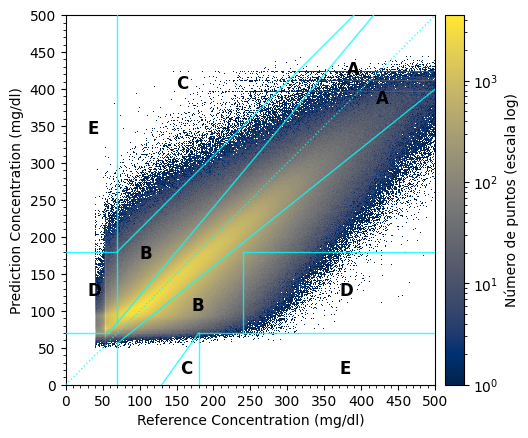

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import PowerNorm

def clarke_error_grid_heatmap_single(ref_values, pred_values, title_string, plot_dir='plots'):
    plt.clf()
    ax = plt.gca()

    # --- CONFIGURACIÓN DEL HEATMAP ---
    # Usamos un solo colormap. 'viridis', 'magma' o 'inferno' son excelentes para densidad.
    # n_bins=100 significa que cada cuadro es de 5x5 mg/dl (500/100).
    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Dibujamos el histograma 2D global
    # norm='log' es fundamental para ver errores raros y densidad alta a la vez.
    h = ax.hist2d(ref_values, pred_values,
                  bins=[n_bins, n_bins],
                  range=h_range,
                  cmap='cividis',
                  cmin=1,
                  norm='log',
                  # alpha=0.8
                  )  # alpha para que las líneas del grid se vean mejor

    # Añadimos una barra de color para que se entienda la escala de densidad
    cb = plt.colorbar(h[3], ax=ax, pad=0.02)
    cb.set_label('Número de puntos (escala log)')

    # 2. Configuración de ejes (Tu estándar)
    plt.xlabel("Reference Concentration (mg/dl)")
    plt.ylabel("Prediction Concentration (mg/dl)")
    plt.xticks(np.arange(0, 551, 50))
    plt.yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del Clarke Error Grid (Z-order alto para que brillen sobre el mapa)
    lp = {'c': 'cyan', 'linewidth': 1, 'zorder': 10, 'alpha': 0.8}  # Cyan destaca bien sobre fondo oscuro

    plt.plot([0, 500], [0, 500], ':', **lp)
    plt.plot([0, 175 / 3], [70, 70], '-', **lp)
    plt.plot([175 / 3, 500 / 1.2], [70, 500], '-', **lp)
    plt.plot([70, 70], [84, 500], '-', **lp)
    plt.plot([0, 70], [180, 180], '-', **lp)
    plt.plot([70, 390], [180, 500], '-', **lp)
    plt.plot([70, 70], [0, 56], '-', **lp)
    plt.plot([70, 500], [56, 400], '-', **lp)
    plt.plot([180, 180], [0, 70], '-', **lp)
    plt.plot([180, 500], [70, 70], '-', **lp)
    plt.plot([240, 240], [70, 180], '-', **lp)
    plt.plot([240, 500], [180, 180], '-', **lp)
    plt.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas
    zones = [(380, 420, "A"), (420, 380, "A"), (170, 100, "B"), (100, 170, "B"),
             (150, 400, "C"), (155, 15, "C"), (30, 120, "D"), (370, 120, "D"),
             (30, 340, "E"), (370, 15, "E")]
    for x, y, txt in zones:
        plt.text(x, y, txt, fontsize=12, fontweight='bold', color='Black', zorder=11)

    plt.savefig(f'{plot_dir}/CEG_Heatmap_Global_{title_string}.png', dpi=300, bbox_inches='tight')
  

clarke_error_grid_heatmap_single(ref_values=df['y_test'],
                                     pred_values=df['y_predict'],
                                     title_string='Test_heatmap_single_log_YlOrRd_bins500')



  

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm  # Importante para asegurar el escalado log

def clarke_error_grid_heatmap_single(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    # --- CONFIGURACIÓN DEL HEATMAP ---
    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Dibujamos el histograma 2D global usando el parámetro cmap_name
    h = ax.hist2d(ref_values, pred_values,
                  bins=[n_bins, n_bins],
                  range=h_range,
                  cmap=cmap_name,
                  cmin=1,
                  norm=LogNorm(), # Usamos LogNorm explícito para evitar problemas
                  zorder=1
                  )

    # Añadimos una barra de color
    cb = plt.colorbar(h[3], ax=ax, pad=0.02)
    cb.set_label(f'Número de puntos (Escala Log) - {cmap_name}')

    # 2. Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del Clarke Error Grid (Cian resalta en mapas oscuros, Negro en claros)
    # Si el cmap es muy claro, quizás quieras cambiar el color de la línea a 'black'
    line_color = 'cyan' if cmap_name in ['magma', 'inferno', 'viridis', 'cividis', 'plasma'] else 'black'
    lp = {'c': line_color, 'linewidth': 1.2, 'zorder': 10, 'alpha': 0.8}

    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175 / 3], [70, 70], '-', **lp)
    ax.plot([175 / 3, 500 / 1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas
    text_color = 'white' if line_color == 'cyan' else 'black'
    zones = [(380, 420, "A"), (420, 380, "A"), (170, 100, "B"), (100, 170, "B"),
             (150, 400, "C"), (155, 15, "C"), (30, 120, "D"), (370, 120, "D"),
             (30, 340, "E"), (370, 15, "E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color=text_color, zorder=11)

    # El nombre del archivo ahora incluye el nombre del cmap
    filename = f"{plot_dir}/CEG_Heatmap_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# --- EJECUCIÓN CON MÚLTIPLES CMAPS ---

# Vector con las opciones de mapas de colores
cmaps_to_test = [
    'viridis', 'magma', 'inferno', 'plasma', 'cividis', # Perceptualmente uniformes
    'YlOrRd', 'Reds', 'Blues', 'GnBu',                # Secuenciales
    'hot', 'afmhot'                                    # Térmicos
]

for cmap in cmaps_to_test:
    print(f"Generando gráfica con cmap: {cmap}...")
    clarke_error_grid_heatmap_single(
        ref_values=df['y_test'],
        pred_values=df['y_predict'],
        title_string='Analysis_2026',
        cmap_name=cmap
    )

Generando gráfica con cmap: viridis...
Generando gráfica con cmap: magma...
Generando gráfica con cmap: inferno...
Generando gráfica con cmap: plasma...
Generando gráfica con cmap: cividis...
Generando gráfica con cmap: YlOrRd...
Generando gráfica con cmap: Reds...
Generando gráfica con cmap: Blues...
Generando gráfica con cmap: GnBu...
Generando gráfica con cmap: hot...
Generando gráfica con cmap: afmhot...


<Figure size 640x480 with 0 Axes>

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_heatmap_with_ranges(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8)) # Un poco más ancho para la colorbar

    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Mapa de calor
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=1)

    cb = plt.colorbar(h[3], ax=ax, pad=0.08) # Más pad para no chocar con marcas
    cb.set_label(f'Densidad (Log) - {cmap_name}')

    # --- DEFINICIÓN DE RANGOS CLÍNICOS ---
    # Rangos: (inicio, fin, color, sigla)
    ranges = [
        (0, 54, 'indianred', 'VH'),    # Very Hypo
        (54, 70, 'red', 'H'),          # Hypo
        (70, 180, 'limegreen', 'E'),   # Euglycemic
        (180, 250, 'yellow', 'Hi'),    # Hyper
        (250, 500, 'orange', 'VHi')    # Very Hyper
    ]

    for start, end, color, label in ranges:
        # A. Líneas verticales discontinuas (muy sutiles)
        ax.axvline(x=end, color='gray', linestyle='--', linewidth=0.8, alpha=0.3, zorder=2)
        
        # B. Marcadores de color en la base (suelo del eje X)
        ax.plot([start, end], [0, 0], color=color, linewidth=6, solid_capstyle='butt', zorder=12)
        
        # C. Etiquetas de siglas en el eje X
        mid_point = (start + end) / 2
        ax.text(mid_point, -15, label, color=color, fontsize=10, 
                fontweight='bold', ha='center', va='top')

    # 2. Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)", labelpad=20)
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    
    # Marcadores estándar
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del CEG (Cian para contraste)
    lp = {'c': 'cyan', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas del Grid (A, B, C, D, E)
    zones = [(380,420,"A"),(420,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, color='white', fontsize=12, fontweight='bold', zorder=11, alpha=0.8)

    plt.savefig(f"{plot_dir}/CEG_Heatmap_Labeled_{cmap_name}_{title_string}.png", dpi=300, bbox_inches='tight')
    plt.close()

# Ejecutar el bucle
test_cmaps = ['magma', 'viridis', 'YlOrRd']
for cm in test_cmaps:
    clarke_error_grid_heatmap_with_ranges(df['y_test'], df['y_predict'], "Comparison", cm)

<Figure size 640x480 with 0 Axes>

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_heatmap_black_labels(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8))

    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Mapa de calor (Heatmap)
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=1)

    cb = plt.colorbar(h[3], ax=ax, pad=0.08)
    cb.set_label(f'Densidad (Log) - {cmap_name}')

    # --- DEFINICIÓN DE RANGOS (TODO EN NEGRO) ---
    # (inicio, fin, sigla)
    ranges = [
        (0, 54, 'TBR_2'),
        (54, 70, 'TBR_1'),
        (70, 180, 'TIR'),
        (180, 250, 'TAR_1'),
        (250, 500, 'TAR_2')
    ]

    for start, end, label in ranges:
        # Líneas verticales divisorias de rangos (Negras, discontinuas y finas)
        if end < 500: # No pintar la línea final del gráfico
            ax.axvline(x=end, color='black', linestyle='--', linewidth=0.7, alpha=0.5, zorder=2)
        
        # Etiquetas de siglas debajo del eje X
        mid_point = (start + end) / 2
        ax.text(mid_point, -18, label, color='black', fontsize=9, 
                fontweight='bold', ha='center', va='top')

    # 2. Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)", labelpad=25, fontweight='bold')
    ax.set_ylabel("Prediction Concentration (mg/dl)", fontweight='bold')
    
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del CEG (Negras para uniformidad)
    # He subido ligeramente el grosor para que no se pierdan con el heatmap
    lp = {'c': 'black', 'linewidth': 1.1, 'zorder': 10, 'alpha': 0.8}
    
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Títulos de zonas del Grid (A, B, C, D, E) en Negro
    zones = [(380,420,"A"),(420,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        # Añadimos un pequeño "glow" o fondo blanco muy sutil si el mapa es muy oscuro
        ax.text(x, y, txt, color='black', fontsize=13, fontweight='black', 
                zorder=11, path_effects=None) # Si no se lee, se puede añadir path_effects

    plt.savefig(f"{plot_dir}/CEG_Heatmap_BlackLabels_{cmap_name}_{title_string}.png", dpi=300, bbox_inches='tight')
    plt.close()

# Bucle para generar versiones con diferentes cmaps
test_cmaps = ['YlOrRd', 'viridis', 'magma', 'Greys']
for cm in test_cmaps:
    clarke_error_grid_heatmap_black_labels(df['y_test'], df['y_predict'], "Black_Version", cm)

<Figure size 640x480 with 0 Axes>

KeyboardInterrupt: 

<Figure size 640x480 with 0 Axes>

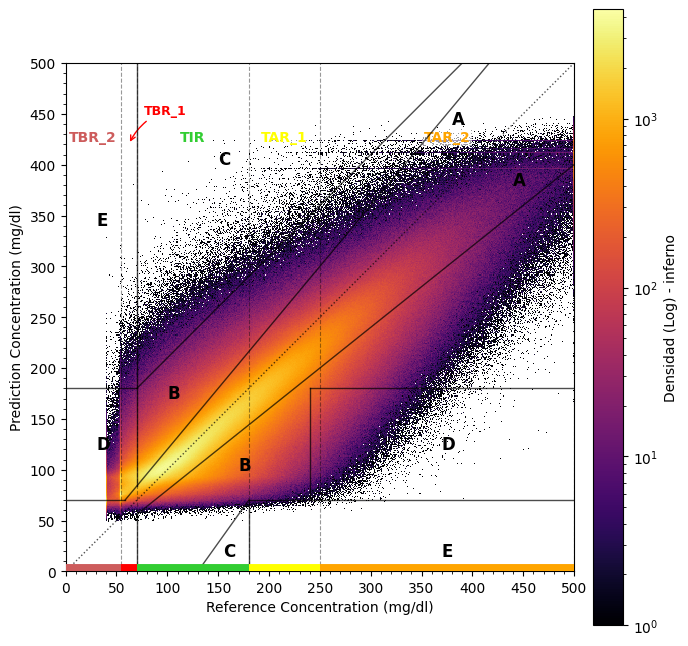

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_final_heatmap(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Mapa de calor
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=1)

    # Barra de color con nombre del mapa
    cb = plt.colorbar(h[3], ax=ax, pad=0.03)
    cb.set_label(f'Densidad (Log) - {cmap_name}')

    # --- RANGOS CLÍNICOS ---
    ranges = [
        (0, 54, 'indianred', 'TBR_2'),
        (54, 70, 'red', 'TBR_1'),
        (70, 180, 'limegreen', 'TIR'),
        (180, 250, 'yellow', 'TAR_1'),
        (250, 500, 'orange', 'TAR_2')
    ]

    y_labels = 420  # Altura flotante para las etiquetas

    for start, end, color, label in ranges:
        # A. Barras de color en la base (eje X)
        ax.plot([start, end], [0, 0], color=color, linewidth=10, solid_capstyle='butt', zorder=12)
        
        # B. Líneas verticales de delimitación (negras y discontinuas)
        ax.axvline(x=end, color='black', linestyle='--', linewidth=0.8, alpha=0.4, zorder=2)
        
        # C. Etiquetas flotantes
        mid_point = (start + end) / 2
        
        if label == 'TBR_1':
            # Estrategia para TBR_1 (rango estrecho): Desplazar texto y poner flecha
            ax.annotate(label, xy=(mid_point, y_labels), xytext=(mid_point + 15, y_labels + 30),
                        color=color, fontweight='bold', fontsize=9,
                        arrowprops=dict(arrowstyle="->", color=color, connectionstyle="arc3,rad=.2"))
        else:
            ax.text(mid_point, y_labels, label, color=color, fontsize=10, 
                    fontweight='bold', ha='center', va='bottom', 
                    bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1))

    # 2. Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del CEG (Todas Negras como pediste)
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.7}
    
    plt.plot([0, 500], [0, 500], ':', **lp)
    plt.plot([0, 175/3], [70, 70], '-', **lp)
    plt.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    plt.plot([70, 70], [84, 500], '-', **lp)
    plt.plot([0, 70], [180, 180], '-', **lp)
    plt.plot([70, 390], [180, 500], '-', **lp)
    plt.plot([70, 70], [0, 56], '-', **lp)
    plt.plot([70, 500], [56, 400], '-', **lp)
    plt.plot([180, 180], [0, 70], '-', **lp)
    plt.plot([180, 500], [70, 70], '-', **lp)
    plt.plot([240, 240], [70, 180], '-', **lp)
    plt.plot([240, 500], [180, 180], '-', **lp)
    plt.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de zonas CEG (A, B, C, D, E) en negro
    zones = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, color='black', fontsize=12, fontweight='bold', zorder=11)

    filename = f"{plot_dir}/CEG_Final_Heatmap_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Bucle de cmaps
test_cmaps = ['viridis', 'YlOrRd', 'magma', 'inferno', 'GnBu']
for cm in test_cmaps:
    clarke_error_grid_final_heatmap(df['y_test'], df['y_predict'], "Glucose_Study", cm)

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_final_heatmap(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Mapa de calor
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=1)

    cb = plt.colorbar(h[3], ax=ax, pad=0.03)
    cb.set_label(f'Densidad (Log) - {cmap_name}')

    # --- RANGOS CLÍNICOS ACTUALIZADOS ---
    # Sustituimos 'limegreen' por 'seagreen' para mejor contraste
    ranges = [
        (0, 54, 'indianred', 'TBR_2'),
        (54, 70, 'red', 'TBR_1'),
        (70, 180, 'seagreen', 'TIR'), 
        (180, 250, 'gold', 'TAR_1'),   # 'gold' suele verse mejor que 'yellow' puro
        (250, 500, 'orange', 'TAR_2')
    ]

    # Altura de las etiquetas justo encima del eje X
    y_label_pos = 8 

    for start, end, color, label in ranges:
        # A. Barras de color en la base (sobre el eje X)
        ax.plot([start, end], [0, 0], color=color, linewidth=12, solid_capstyle='butt', zorder=12)
        
        # B. Líneas verticales (negras discontinuas)
        ax.axvline(x=end, color='black', linestyle='--', linewidth=0.8, alpha=0.3, zorder=2)
        
        # C. Etiquetas justo encima del eje
        mid_point = (start + end) / 2
        
        if label == 'TBR_1':
            # TBR_1 sigue necesitando un pequeño ajuste para no solaparse con TBR_2
            ax.text(mid_point, y_label_pos + 15, label, color=color, fontsize=8, 
                    fontweight='bold', ha='center', rotation=90, va='bottom')
        else:
            ax.text(mid_point, y_label_pos, label, color=color, fontsize=9, 
                    fontweight='bold', ha='center', va='bottom',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5))

    # 2. Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Líneas del CEG (Todas Negras)
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}
    
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de zonas (A, B, C, D, E)
    zones = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, color='black', fontsize=12, fontweight='bold', zorder=11)

    filename = f"{plot_dir}/CEG_Final_Heatmap_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Prueba con tus cmaps favoritos
for cm in ['viridis', 'YlOrRd', 'magma']:
    clarke_error_grid_final_heatmap(df['y_test'], df['y_predict'], "Final_Version", cm)

<Figure size 640x480 with 0 Axes>

Procesando: viridis
Procesando: plasma
Procesando: inferno
Procesando: magma
Procesando: cividis
Procesando: YlOrRd
Procesando: GnBu
Procesando: Blues


KeyboardInterrupt: 

<Figure size 640x480 with 0 Axes>

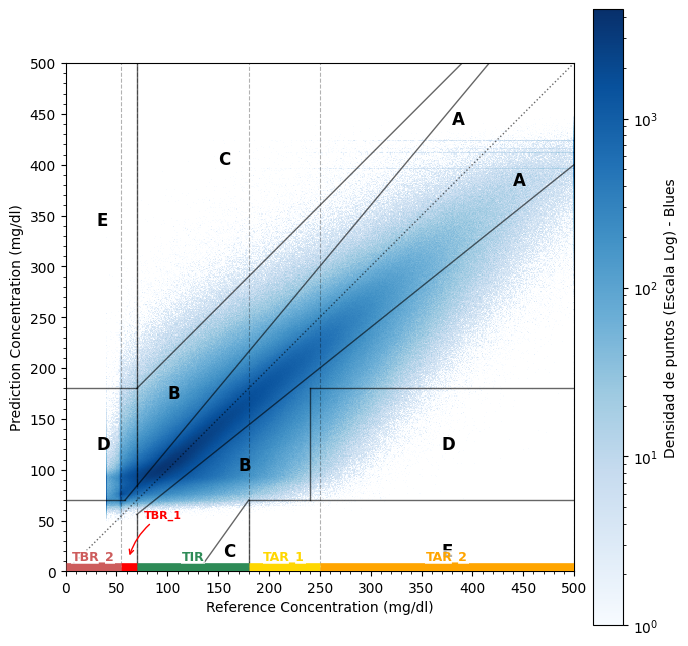

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_final_heatmap(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    # Crear directorio si no existe
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    n_bins = 500
    h_range = [[0, 500], [0, 500]]

    # 1. Mapa de calor (Heatmap)
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=1)

    # Configuración de la Colorbar
    cb = plt.colorbar(h[3], ax=ax, pad=0.03)
    cb.set_label(f'Densidad de puntos (Escala Log) - {cmap_name}')

    # --- RANGOS CLÍNICOS (Eje X) ---
    # Usamos 'seagreen' para TIR y 'gold' para TAR_1 por legibilidad
    ranges = [
        (0, 54, 'indianred', 'TBR_2'),
        (54, 70, 'red', 'TBR_1'),
        (70, 180, 'seagreen', 'TIR'), 
        (180, 250, 'gold', 'TAR_1'),
        (250, 500, 'orange', 'TAR_2')
    ]

    y_label_base = 8 # Altura justo encima del eje X

    for start, end, color, label in ranges:
        # A. Barras de color sólidas en el suelo del gráfico
        ax.plot([start, end], [0, 0], color=color, linewidth=12, solid_capstyle='butt', zorder=12)
        
        # B. Líneas verticales de referencia (negras, discontinuas y suaves)
        ax.axvline(x=end, color='black', linestyle='--', linewidth=0.8, alpha=0.3, zorder=2)
        
        # C. Etiquetas de los rangos
        mid_point = (start + end) / 2
        
        if label == 'TBR_1':
            # Truco de la flecha para el rango estrecho de TBR_1
            ax.annotate(label, xy=(mid_point, y_label_base + 5), 
                        xytext=(mid_point + 15, y_label_base + 45),
                        color=color, fontweight='bold', fontsize=8,
                        arrowprops=dict(arrowstyle="->", color=color, connectionstyle="arc3,rad=.2"),
                        zorder=13)
        else:
            # Etiquetas estándar con fondo blanco para contraste
            ax.text(mid_point, y_label_base, label, color=color, fontsize=9, 
                    fontweight='bold', ha='center', va='bottom',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5),
                    zorder=13)

    # 2. Configuración de Ejes y Estética
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    # 3. Dibujo de las Líneas del Clarke Error Grid (Todas Negras)
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}
    
    # Líneas principales y diagonales
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de las Zonas A-E (en Negro)
    zones = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
             (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
             (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones:
        ax.text(x, y, txt, color='black', fontsize=12, fontweight='bold', zorder=11)

    # Guardado dinámico
    filename = f"{plot_dir}/CEG_Heatmap_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# --- BUCLE PARA TODAS LAS OPCIONES DE CMAP ---

cmaps_para_probar = [
    'viridis', 'plasma', 'inferno', 'magma', 'cividis', # Perceptualmente uniformes
    'YlOrRd', 'GnBu', 'Blues', 'Reds',                # Secuenciales
    'hot', 'afmhot', 'gist_heat'                       # Térmicos / Contraste
]

for cmap in cmaps_para_probar:
    print(f"Procesando: {cmap}")
    clarke_error_grid_final_heatmap(
        ref_values=df['y_test'], 
        pred_values=df['y_predict'], 
        title_string="Final_Analysis_2026", 
        cmap_name=cmap
    )

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_background_zones(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    # --- 1. PINTAR EL FONDO POR FRANJAS (ZONAS CLÍNICAS) ---
    # Usamos alfas muy bajos (0.1 - 0.2) para que el fondo sea sutil
    zones_bg = [
        (0, 54, '#f2d7d5', 'TBR_2'),    # Rojo muy pálido
        (54, 70, '#f9ebea', 'TBR_1'),   # Rojo más pálido aún
        (70, 180, '#e9f7ef', 'TIR'),    # Verde pálido
        (180, 250, '#fef9e7', 'TAR_1'), # Amarillo pálido
        (250, 500, '#fdf2e9', 'TAR_2')  # Naranja pálido
    ]

    for start, end, color, label in zones_bg:
        ax.axvspan(start, end, facecolor=color, alpha=1, zorder=0)
        
        # Etiquetas de los rangos en la parte superior (y=480)
        mid_point = (start + end) / 2
        ax.text(mid_point, 480, label, color='gray', fontsize=8, 
                fontweight='bold', ha='center', alpha=0.6, zorder=1)

    # --- 2. MAPA DE CALOR ---
    n_bins = 500
    h_range = [[0, 500], [0, 500]]
    
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=3)

    cb = plt.colorbar(h[3], ax=ax, pad=0.03)
    cb.set_label(f'Densidad (Log) - {cmap_name}')

    # --- 3. LÍNEAS DEL CLARKE ERROR GRID (NEGRAS) ---
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.5}
    
    # Dibujamos las líneas clásicas del CEG
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de las Zonas A-E
    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, color='black', fontsize=12, fontweight='bold', zorder=11, alpha=0.7)

    # --- 4. CONFIGURACIÓN FINAL ---
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_ZonesBG_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Bucle para todos los cmaps
cmaps = ['viridis', 'magma', 'YlOrRd', 'GnBu', 'inferno']
for cm in cmaps:
    clarke_error_grid_background_zones(df['y_test'], df['y_predict'], "Comparison", cm)

<Figure size 640x480 with 0 Axes>

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm

def clarke_error_grid_vibrant_bg(ref_values, pred_values, title_string, cmap_name, plot_dir='plots2'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(8, 8))

    # --- 1. FONDO DE RANGOS (Colores originales suavizados) ---
    # Usamos un alpha bajo (0.15) para que el heatmap resalte sobre ellos
    zones_bg = [
        (0, 54, 'indianred', 'TBR_2'),
        (54, 70, 'red', 'TBR_1'),
        (70, 180, 'seagreen', 'TIR'), 
        (180, 250, 'gold', 'TAR_1'),
        (250, 500, 'orange', 'TAR_2')
    ]

    for start, end, color, label in zones_bg:
        # Pintar la franja de fondo
        ax.axvspan(start, end, facecolor=color, alpha=0.15, zorder=0)
        
        # Etiquetas flotantes que destaquen
        mid_point = (start + end) / 2
        # Ponemos las etiquetas en la parte superior con un "box" estilizado
        ax.text(mid_point, 475, label, color=color, fontsize=10, 
                fontweight='bold', ha='center', va='center',
                bbox=dict(facecolor='white', alpha=0.9, edgecolor=color, 
                          boxstyle='round,pad=0.5', linewidth=1.5),
                zorder=15)

    # --- 2. MAPA DE CALOR ---
    n_bins = 500
    h_range = [[0, 500], [0, 500]]
    
    h = ax.hist2d(ref_values, pred_values, bins=n_bins, range=h_range, 
                  cmap=cmap_name, cmin=1, norm=LogNorm(), zorder=3)

    # Barra de color integrada
    cb = plt.colorbar(h[3], ax=ax, pad=0.03)
    cb.set_label(f'Log Densidad - {cmap_name}')

    # --- 3. LÍNEAS DEL CEG (Negras para máxima claridad) ---
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Zonas del CEG (A, B, C, D, E)
    zones_ceg = [(380,430,"A"),(430,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, color='black', fontsize=13, fontweight='black', zorder=12)

    # --- 4. CONFIGURACIÓN DE EJES ---
    ax.set_xlabel("Reference Glucose (mg/dL)")
    ax.set_ylabel("Predicted Glucose (mg/dL)")
    ax.set_xticks(np.arange(0, 501, 50))
    ax.set_yticks(np.arange(0, 501, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_VibrantBG_{cmap_name}_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Ejecución masiva con todos los estilos
cmaps = ['viridis', 'plasma', 'magma', 'inferno', 'YlOrRd', 'GnBu', 'hot']
for cm in cmaps:
    print(f"Generando versión: {cm}")
    clarke_error_grid_vibrant_bg(df['y_test'], df['y_predict'], "Comparison_2026", cm)

Generando versión: viridis
Generando versión: plasma
Generando versión: magma
Generando versión: inferno
Generando versión: YlOrRd
Generando versión: GnBu
Generando versión: hot


<Figure size 640x480 with 0 Axes>

# Split representation

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def clarke_error_grid_semantic_heatmap(ref_values, pred_values, title_string, plot_dir='plots_semantic'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8)) # Un poco más ancho para la leyenda

    # --- 1. CONFIGURACIÓN GLOBAL (CRÍTICO) ---
    # Definimos los bins y el rango una sola vez para que todos los trozos encajen perfectos
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # Hacemos un histograma "invisible" con TODOS los datos para obtener la escala real (vmin, vmax)
    # Esto asegura que la intensidad sea comparable entre zonas.
    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    # Obtenemos el conteo mínimo y máximo global
    vmin_global = np.nanmin(h_global[0]) # El mínimo no cero
    vmax_global = np.nanmax(h_global[0])

    # Definimos la normalización compartida
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. DEFINICIÓN DE COLORES SEMÁNTICOS ---
    # Creamos mapas de color personalizados que van de BLANCO al COLOR DESEADO
    # Esto es vital para que el fondo sea blanco uniforme.
    
    # Rango 1: < 54 (Hipo severa) -> Rojo Oscuro / Vino
    cmap_tbr2 = LinearSegmentedColormap.from_list("custom_tbr2", ["#ffffff", "#8b0000"]) 
    
    # Rango 2: 54-70 (Hipo) -> Rojo
    cmap_tbr1 = LinearSegmentedColormap.from_list("custom_tbr1", ["#ffffff", "#ff0000"])
    
    # Rango 3: 70-180 (TIR) -> Verde (usamos un verde clínico agradable)
    cmap_tir = LinearSegmentedColormap.from_list("custom_tir", ["#ffffff", "#00a651"])
    
    # Rango 4: 180-250 (Hiper) -> Amarillo
    cmap_tar1 = LinearSegmentedColormap.from_list("custom_tar1", ["#ffffff", "#ffd700"])
    
    # Rango 5: > 250 (Hiper severa) -> Naranja
    cmap_tar2 = LinearSegmentedColormap.from_list("custom_tar2", ["#ffffff", "#ff8c00"])

    # --- 3. DIBUJO POR CAPAS (ZONAS) ---
    # Cortamos los datos, pero usamos la normalización global
    
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins,
                      range=my_range,
                      cmap=cmap,
                      cmin=1,        # Solo pintar si hay al menos 1 punto
                      norm=global_norm, # <--- LA CLAVE: Todos comparten la escala de intensidad
                      zorder=2)

    # --- 4. LEYENDA EN ESCALA DE GRISES (EL TRADUCTOR) ---
    # Creamos un mapa "falso" en grises solo para dibujar la barra
    sm = plt.cm.ScalarMappable(norm=global_norm, cmap='Greys')
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.03)
    cb.set_label('Densidad de puntos (Escala Logarítmica Global)')
    
    # Opcional: Añadir marcas visuales en la colorbar
    # cb.ax.minorticks_on()

    # --- 5. LÍNEAS DEL CEG Y ESTÉTICA ---
    # Usamos gris oscuro o negro para las líneas, ya que tenemos colores variados
    lp = {'c': 'black', 'linewidth': 1, 'zorder': 10, 'alpha': 0.6}

    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas de zonas A-E
    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.7, zorder=11)

    # Configuración de ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_Semantic_Heatmap_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# --- EJECUCIÓN ---
print("Generando Heatmap Semántico...")
clarke_error_grid_semantic_heatmap(df['y_test'], df['y_predict'], 'MultiColor_Analysis')

Generando Heatmap Semántico...


<Figure size 640x480 with 0 Axes>

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def clarke_error_grid_semantic_heatmap_deep(ref_values, pred_values, title_string, plot_dir='plots_semantic_deep'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8))

    # --- 1. CONFIGURACIÓN GLOBAL ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # Calculamos vmin/vmax globales para que la escala sea justa
    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    vmin_global = np.nanmin(h_global[0])
    vmax_global = np.nanmax(h_global[0])
    
    # Normalización Logarítmica Global
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. COLORES PROFUNDOS (LA SOLUCIÓN) ---
    # La clave: Añadimos un tercer color al final que es una versión MUY oscura del tono.
    # Así, la alta densidad se verá casi negra (o muy intensa) en todas las zonas.

    # Hipo Severa (<54): Blanco -> Rojo -> Vino Oscuro
    cmap_tbr2 = LinearSegmentedColormap.from_list("deep_tbr2", ["#ffffff", "#ff4d4d", "#4a0000"]) 
    
    # Hipo (54-70): Blanco -> Rojo Claro -> Rojo Sangre
    cmap_tbr1 = LinearSegmentedColormap.from_list("deep_tbr1", ["#ffffff", "#ff6666", "#8b0000"])
    
    # TIR (70-180): Blanco -> Verde Lima -> Verde Bosque Profundo (Casi negro)
    # Esto hará que la diagonal central se vea muy densa
    cmap_tir = LinearSegmentedColormap.from_list("deep_tir", ["#ffffff", "#32CD32", "#004d00"])
    
    # Hiper (180-250): Blanco -> Amarillo -> Ocre/Marrón Dorado
    # Vital: El amarillo puro no se ve, el ocre sí representa densidad
    cmap_tar1 = LinearSegmentedColormap.from_list("deep_tar1", ["#ffffff", "#FFD700", "#6b5700"])
    
    # Hiper Severa (>250): Blanco -> Naranja -> Marrón Café
    cmap_tar2 = LinearSegmentedColormap.from_list("deep_tar2", ["#ffffff", "#FF8C00", "#5c2a00"])

    # --- 3. DIBUJO ---
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins,
                      range=my_range,
                      cmap=cmap,
                      cmin=1,
                      norm=global_norm, 
                      zorder=2)

    # --- 4. LEYENDA (TRADUCTOR DE INTENSIDAD) ---
    sm = plt.cm.ScalarMappable(norm=global_norm, cmap='Greys')
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.03)
    cb.set_label('Densidad de puntos (Cuanto más oscuro, más puntos)')

    # --- 5. ESTÉTICA ---
    # Líneas negras finas para que se vean bien sobre los colores claros y oscuros
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}

    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)

    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500])
    ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_Semantic_Deep_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# --- EJECUCIÓN ---
print("Generando Heatmap Semántico Profundo...")
clarke_error_grid_semantic_heatmap_deep(df['y_test'], df['y_predict'], 'Deep_Analysis')

Generando Heatmap Semántico Profundo...


<Figure size 640x480 with 0 Axes>

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def clarke_error_grid_high_contrast(ref_values, pred_values, title_string, plot_dir='plots_high_contrast'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8))

    # --- 1. CONFIGURACIÓN GLOBAL DE DENSIDAD ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # Calculamos la densidad global para que todos compitan en igualdad de condiciones
    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    vmin_global = np.nanmin(h_global[0])
    vmax_global = np.nanmax(h_global[0])
    
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. PALETA "JEWEL TONES" (ALTO CONTRASTE) ---
    # Estrategia: Blanco -> Color Vibrante -> Color CASI NEGRO
    # Al terminar todos en un tono muy oscuro, la densidad máxima se ve igual en todas las zonas.

    # Rango 1 (<54): Púrpura Profundo (Deep Purple)
    # Se distingue muy bien del blanco y del azul.
    cmap_1 = LinearSegmentedColormap.from_list("jewel_purple", ["#ffffff", "#9400d3", "#2e004f"]) 
    
    # Rango 2 (54-70): Azul Zafiro (Sapphire Blue)
    cmap_2 = LinearSegmentedColormap.from_list("jewel_blue", ["#ffffff", "#0000ff", "#00005c"])
    
    # Rango 3 (70-180): Verde Azulado/Petróleo (Deep Teal) - LA CLAVE
    # El verde normal es débil. El Teal tiene componente azul que le da "cuerpo" visual.
    cmap_3 = LinearSegmentedColormap.from_list("jewel_teal", ["#ffffff", "#008080", "#002b2b"])
    
    # Rango 4 (180-250): Rojo Rubí (Ruby Red)
    # Sustituimos el amarillo (invisible) por rojo naranja intenso.
    cmap_4 = LinearSegmentedColormap.from_list("jewel_red", ["#ffffff", "#ff4500", "#4d1500"])
    
    # Rango 5 (>250): Naranja Quemado -> Chocolate (Burnt Orange)
    # SUSTITUCIÓN: Usamos un naranja que acaba en marrón café muy oscuro.
    # Esto elimina el problema del amarillo invisible y no confunde con la escala de grises.
    cmap_5 = LinearSegmentedColormap.from_list("jewel_burnt_orange", ["#ffffff", "#ff8c00", "#4a2500"])

    # --- 3. DIBUJO ---
    ranges = [
        (ref_values < 54, cmap_1),
        ((ref_values >= 54) & (ref_values < 70), cmap_2),
        ((ref_values >= 70) & (ref_values <= 180), cmap_3),
        ((ref_values > 180) & (ref_values <= 250), cmap_4),
        (ref_values > 250, cmap_5)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins,
                      range=my_range,
                      cmap=cmap,
                      cmin=1,
                      norm=global_norm, 
                      zorder=2)

    # --- 4. LEYENDA Y ESTÉTICA ---
    sm = plt.cm.ScalarMappable(norm=global_norm, cmap='Greys')
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.03)
    cb.set_label('Densidad de puntos (Log Scale) - Más oscuro = Más datos')

    # Líneas
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.4}
    ax.plot([0, 500], [0, 500], ':', **lp)
    # ... (resto de líneas CEG igual que siempre) ...
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas (Color negro para máxima legibilidad)
    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.5, zorder=11)

    # Ajustes finales
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_HighContrast_Jewel_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Ejecución
clarke_error_grid_high_contrast(df['y_test'], df['y_predict'], 'Eye_Perfect')

<Figure size 640x480 with 0 Axes>

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def clarke_error_grid_multi_style(ref_values, pred_values, title_string, plot_dir='plots_multi_style'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8))

    # --- 1. NORMALIZACIÓN GLOBAL ---
    # Calculamos la densidad total para que todos los estilos compartan la misma escala matemática
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    vmin_global = np.nanmin(h_global[0])
    vmax_global = np.nanmax(h_global[0])
    
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. CREACIÓN DE ESTILOS MULTI-TONO (ESTILO "PLASMA" POR ZONAS) ---
    # La clave aquí es usar 4 pasos: Blanco -> Brillo -> Color Principal -> Oscuridad
    # Esto da esa sensación de "relieve" que buscas.

    # Rango 1 (<54): Estilo "Nebula" (Púrpuras complejos)
    # Blanco -> Rosa -> Violeta -> Negro
    cmap_1 = LinearSegmentedColormap.from_list("style_hypo_sev", 
                                               ["#ffffff", "#ff80ff", "#800080", "#1a001a"]) 
    
    # Rango 2 (54-70): Estilo "Lava" (Rojos dinámicos)
    # Blanco -> Naranja Claro -> Rojo Fuego -> Granate Oscuro
    cmap_2 = LinearSegmentedColormap.from_list("style_hypo", 
                                               ["#ffffff", "#ffcc00", "#ff0000", "#4d0000"])
    
    # Rango 3 (70-180): Estilo "Océano/Esmeralda" (TIR - El más importante)
    # Blanco -> Cyan (Turquesa) -> Verde Esmeralda -> Azul Petróleo Profundo
    # Esta transición (Cyan a Verde a Azul) es la que da esa riqueza visual increíble.
    cmap_3 = LinearSegmentedColormap.from_list("style_tir", 
                                               ["#ffffff", "#00ffff", "#00cc44", "#003366"])
    
    # Rango 4 (180-250): Estilo "Ámbar" (Hiper)
    # Blanco -> Amarillo Limón -> Naranja Intenso -> Marrón Óxido
    cmap_4 = LinearSegmentedColormap.from_list("style_hyper", 
                                               ["#ffffff", "#fff700", "#ff8c00", "#663300"])
    
    # Rango 5 (>250): Estilo "Eclipse" (Hiper Severa)
    # Blanco -> Cobre -> Marrón Café -> Negro
    cmap_5 = LinearSegmentedColormap.from_list("style_hyper_sev", 
                                               ["#ffffff", "#d2691e", "#5c4033", "#000000"])

    # --- 3. DIBUJO ---
    ranges = [
        (ref_values < 54, cmap_1),
        ((ref_values >= 54) & (ref_values < 70), cmap_2),
        ((ref_values >= 70) & (ref_values <= 180), cmap_3),
        ((ref_values > 180) & (ref_values <= 250), cmap_4),
        (ref_values > 250, cmap_5)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            # Pintamos cada zona con su "estilo" propio
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins,
                      range=my_range,
                      cmap=cmap,
                      cmin=1,
                      norm=global_norm, 
                      zorder=2)

    # --- 4. LEYENDA Y DETALLES ---
    # Mantenemos la leyenda en grises para explicar la densidad
    sm = plt.cm.ScalarMappable(norm=global_norm, cmap='Greys')
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.03)
    cb.set_label('Densidad de puntos (Log) - Mapeo de Intensidad Global')

    # Líneas
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Textos
    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)

    # Ejes
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_MultiStyle_Texture_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Ejecución

clarke_error_grid_multi_style(df['y_test'], df['y_predict'], 'Rich_Texture')

<Figure size 640x480 with 0 Axes>

# FInal version
## Deep with original colors 

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap

def clarke_error_grid_semantic_heatmap_custom_colors(ref_values, pred_values, title_string, plot_dir='plots_semantic_custom'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(9, 8))

    # --- 1. CONFIGURACIÓN GLOBAL ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # Calculamos límites globales de densidad
    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    vmin_global = np.nanmin(h_global[0])
    vmax_global = np.nanmax(h_global[0])
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. PALETA EXACTA SOLICITADA ---
    # La lógica es: Blanco -> TU COLOR -> Tu color oscurecido (para máxima densidad)
    
    # 1. TBR2 (<54): IndianRed
    # IndianRed es un rojo suave/tierra. Lo oscurecemos hacia un marrón rojizo.
    # Esto lo diferencia claramente del Rojo vivo del rango siguiente.
    cmap_tbr2 = LinearSegmentedColormap.from_list("custom_indian", ["#ffffff", "indianred", "#8B3A3A"]) 
    
    # 2. TBR1 (54-70): Red
    # Rojo puro y vibrante. Lo oscurecemos hacia un granate sangre.
    cmap_tbr1 = LinearSegmentedColormap.from_list("custom_red", ["#ffffff", "red", "#8B0000"])
    
    # 3. TIR (70-180): LimeGreen
    # Verde lima brillante. Lo oscurecemos hacia un verde bosque.
    cmap_tir = LinearSegmentedColormap.from_list("custom_lime", ["#ffffff", "limegreen", "#006400"])
    
    # 4. TAR1 (180-250): Yellow
    # El amarillo es difícil en fondos blancos.
    # El truco: Blanco -> Amarillo Puro -> Olive (Amarillo oscuro). 
    # Así se ve amarillo pero permite ver la densidad máxima.
    cmap_tar1 = LinearSegmentedColormap.from_list("custom_yellow", ["#ffffff", "yellow", "#808000"])
    
    # 5. TAR2 (>250): Orange
    # Naranja puro. Lo oscurecemos hacia un marrón óxido.
    cmap_tar2 = LinearSegmentedColormap.from_list("custom_orange", ["#ffffff", "orange", "#8B4513"])

    # --- 3. DIBUJO ---
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            # Usamos zorder=2 para que quede por debajo de las líneas
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins,
                      range=my_range,
                      cmap=cmap,
                      cmin=1,
                      norm=global_norm, 
                      zorder=2)

    # --- 4. LEYENDA Y ESTÉTICA ---
    # Leyenda en escala de grises para explicar la densidad (independiente del color)
    sm = plt.cm.ScalarMappable(norm=global_norm, cmap='Greys')
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.03)
    cb.set_label('Densidad de puntos (Intensidad)')

    # Líneas de la rejilla Clarke
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    # Etiquetas
    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)

    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_CustomColors_{title_string}.png"
    plt.savefig(filename, dpi=2500, bbox_inches='tight')
    plt.close()

# Ejecución
print("Generando Heatmap con colores oficiales...")
clarke_error_grid_semantic_heatmap_custom_colors(df_t1d_lstm['y_test'], df_t1d_lstm['y_predict'], 'Official_Palette')

Generando Heatmap con colores oficiales...


<Figure size 640x480 with 0 Axes>

## Strip leyend with official colors V1

In [56]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

def clarke_error_grid_striped_legend(ref_values, pred_values, title_string, plot_dir='plots_striped_legend'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots(figsize=(10, 8)) 

    # --- 1. CONFIGURACIÓN Y NORMALIZACIÓN GLOBAL ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    # Evitamos error si el array está vacío o todo es nan
    if len(h_global[0][h_global[0] > 0]) > 0:
        vmin_global = np.nanmin(h_global[0])
        vmax_global = np.nanmax(h_global[0])
    else:
        vmin_global = 1
        vmax_global = 10

    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. DEFINICIÓN DE COLORES ---
    # TBR2: IndianRed -> Marrón Rojizo
    cmap_tbr2 = LinearSegmentedColormap.from_list("custom_indian", ["#ffffff", "indianred", "#8B3A3A"]) 
    # TBR1: Red -> Granate
    cmap_tbr1 = LinearSegmentedColormap.from_list("custom_red", ["#ffffff", "red", "#8B0000"])
    # TIR: LimeGreen -> Verde Bosque
    cmap_tir = LinearSegmentedColormap.from_list("custom_lime", ["#ffffff", "limegreen", "#006400"])
    # TAR1: Yellow -> Olive
    cmap_tar1 = LinearSegmentedColormap.from_list("custom_yellow", ["#ffffff", "yellow", "#808000"])
    # TAR2: Orange -> Marrón Óxido
    cmap_tar2 = LinearSegmentedColormap.from_list("custom_orange", ["#ffffff", "orange", "#8B4513"])

    cmaps_ordered = [cmap_tbr2, cmap_tbr1, cmap_tir, cmap_tar1, cmap_tar2]

    # --- 3. DIBUJO DEL GRÁFICO PRINCIPAL ---
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins, range=my_range, cmap=cmap, cmin=1, norm=global_norm, zorder=2)

    # --- 4. CREACIÓN DE LA LEYENDA (CORREGIDO) ---
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="8%", pad=0.15) 

    # CORRECCIÓN AQUÍ:
    # Para dibujar 200 celdas de color, necesitamos 201 bordes en Y.
    n_steps = 200
    
    # Y_bounds: 201 puntos (los bordes de las celdas)
    Y_bounds = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps + 1)
    
    # Z_values: 200 puntos (el valor de color dentro de la celda)
    # Usamos los mismos valores que los bounds pero quitamos el último para que coincidan las dimensiones
    Z_values = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps)
    Z_slice = Z_values.reshape(-1, 1) # Forma (200, 1)

    for i in range(5):
        # X_bounds: 2 puntos (borde izquierdo y derecho de la franja)
        X_bounds = np.array([i, i+1])
        
        # Meshgrid con las dimensiones correctas:
        # X_mesh: (201, 2)
        # Y_mesh: (201, 2)
        X_mesh, Y_mesh = np.meshgrid(X_bounds, Y_bounds)
        
        # Z_slice tiene forma (200, 1). 
        # pcolormesh(X(N+1), Y(M+1), C(N, M)) -> Esto cumple la regla shading='flat'
        cax.pcolormesh(X_mesh, Y_mesh, Z_slice, 
                       cmap=cmaps_ordered[i], norm=global_norm, shading='flat')

    # Estética de la barra lateral
    cax.set_yscale('log')
    cax.set_xticks([]) 
    cax.set_ylabel('Densidad de puntos (Log)', rotation=270, labelpad=20, fontsize=11)
    cax.set_xlim(0, 5) # Aseguramos que se vean las 5 franjas
    
    # Añadimos etiquetas pequeñas debajo de cada color para identificar qué es (opcional pero útil)
    labels = ["TBR2", "TBR1", "TIR", "TAR1", "TAR2"]
    cax.set_xticks([0.5, 1.5, 2.5, 3.5, 4.5])
    cax.set_xticklabels(labels, rotation=90, fontsize=8)
    cax.tick_params(axis='x', length=0) # Quitar las marcas del tick, dejar solo texto

    # --- 5. DETALLES DE CLARKE Y GUARDADO ---
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)

    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 500]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_StripedLegend_{title_string}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.close()

# Ejecución
print("Generando Heatmap corregido con leyenda de franjas...")
clarke_error_grid_striped_legend(df_t1d_lstm['y_test'], df_t1d_lstm['y_predict'], 'MultiStrip_Fixed')

Generando Heatmap corregido con leyenda de franjas...


<Figure size 640x480 with 0 Axes>

## Strip leyend with official colors V2

In [83]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

def clarke_error_grid_striped_legend_english(ref_values, pred_values, title_string, plot_dir='plots_striped_english'):
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    # fig, ax = plt.subplots(figsize=(10, 8)) 
    fig, ax = plt.subplots() 

    # --- 1. GLOBAL CONFIGURATION ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # Calculate global density limits
    h_global = ax.hist2d(ref_values, pred_values, bins=my_bins, range=my_range, cmin=1, visible=False)
    
    if len(h_global[0][h_global[0] > 0]) > 0:
        vmin_global = np.nanmin(h_global[0])
        vmax_global = np.nanmax(h_global[0])
    else:
        vmin_global = 1; vmax_global = 10

    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- 2. COLOR DEFINITIONS (Official Palette + Darkening) ---
    cmap_tbr2 = LinearSegmentedColormap.from_list("custom_indian", ["#ffffff", "indianred", "#8B3A3A"]) 
    cmap_tbr1 = LinearSegmentedColormap.from_list("custom_red", ["#ffffff", "red", "#8B0000"])
    cmap_tir  = LinearSegmentedColormap.from_list("custom_lime", ["#ffffff", "limegreen", "#006400"])
    cmap_tar1 = LinearSegmentedColormap.from_list("custom_yellow", ["#ffffff", "yellow", "#808000"])
    cmap_tar2 = LinearSegmentedColormap.from_list("custom_orange", ["#ffffff", "orange", "#8B4513"])

    cmaps_ordered = [cmap_tbr2, cmap_tbr1, cmap_tir, cmap_tar1, cmap_tar2]

    # --- 3. MAIN PLOT DRAWING ---
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins, range=my_range, cmap=cmap, cmin=1, norm=global_norm, zorder=2)

    # --- 4. CUSTOM LEGEND BAR (Refined) ---
    divider = make_axes_locatable(ax)
    
    # AJUSTES AQUÍ: 
    # size="4%" (Más estrecha)
    # pad=0.3 (Más separación del gráfico principal)
    cax = divider.append_axes("right", size="5%", pad=0.2) 

    # Drawing the stripes (Same logic as before)
    n_steps = 200
    Y_bounds = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps + 1)
    Z_values = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps)
    Z_slice = Z_values.reshape(-1, 1)

    for i in range(5):
        X_bounds = np.array([i, i+1])
        X_mesh, Y_mesh = np.meshgrid(X_bounds, Y_bounds)
        cax.pcolormesh(X_mesh, Y_mesh, Z_slice, 
                       cmap=cmaps_ordered[i], norm=global_norm, shading='flat')

    # --- 5. LEGEND AESTHETICS (English & Position) ---
    cax.set_yscale('log')
    cax.set_xlim(0, 5)
    
    # Mover Ticks y Label a la DERECHA
    cax.yaxis.tick_right()
    cax.yaxis.set_label_position("right")
    
    # Etiqueta en Inglés
    cax.set_ylabel('Point Density (Log Scale)', rotation=90)
    
    # Etiquetas inferiores (Ranges)
    # labels = ["TBR2", "TBR1", "TIR", "TAR1", "TAR2"]
    # cax.set_xticks([0.5, 1.5, 2.5, 3.5, 4.5])
    cax.set_xticks([])
    # cax.set_xticklabels(labels, rotation=90, fontsize=9)
    # cax.tick_params(axis='x', length=0) 

    # --- 6. CLARKE GRID LINES & LABELS ---
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}
    ax.plot([0, 500], [0, 500], ':', **lp)
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    ax.plot([70, 70], [84, 500], '-', **lp)
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    ax.plot([70, 500], [56, 400], '-', **lp)
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),
                 (30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)

    # --- AXIS LABELS IN ENGLISH ---
    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    
    ax.set_xticks(np.arange(0, 551, 50))
    ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 501]); ax.set_ylim([0, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_Final_English_{title_string}.png"
    plt.savefig(filename, dpi=350, bbox_inches='tight')
    # plt.close()

# Run
# print("Generating Final Polished English Heatmap...")
# clarke_error_grid_striped_legend_english(df_t1d_lstm['y_test'], df_t1d_lstm['y_predict'], 'English_Version')

# Read the data

In [2]:
# Diatrend vectors
df_diatrend_lstm = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_LSTM_H4.parquet')
df_diatrend_linear = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_Linear_H4.parquet')
df_diatrend_cnn = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_CNN_H4.parquet')

#Replace vectors
df_replace_lstm = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_LSTM_H4.parquet')
df_replace_linear = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_Linear_H4.parquet')
df_replace_cnn = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_CNN_H4.parquet')

# T1DiabetesGranada vectors
df_t1d_lstm = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/t1d/df_test_results_vectors_RMSE_LSTM_H4.parquet')
df_t1d_linear = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/t1d/df_test_results_vectors_RMSE_Linear_H4.parquet')
df_t1d_cnn = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/t1d/df_test_results_vectors_RMSE_CNN_H4.parquet')



## Saturate values above 500 and below 0 to 500 and 0 respectively in all dataframes
### Value counts by dataset

In [8]:
# print all values above 500 and below 0 of all dataframes in a regular for loop
for df, model_name in zip([df_diatrend_lstm, df_diatrend_linear, df_diatrend_cnn, df_replace_lstm, df_replace_linear, df_replace_cnn, df_t1d_lstm, df_t1d_linear, df_t1d_cnn],
['LSTM_Diatrend', 'Linear_Diatrend', 'CNN_Diatrend', 'LSTM_Replace', 'Linear_Replace', 'CNN_Replace', 'LSTM_T1DiabetesGranada', 'Linear_T1DiabetesGranada', 'CNN_T1DiabetesGranada']): 
    print(f"Model: {model_name}") 
    print(f"Values > 500: {df[df['y_predict'] > 500].shape[0]}") 
    print(f"Values < 0: {df[df['y_predict'] < 0].shape[0]}") 
    print("")


Model: LSTM_Diatrend
Values > 500: 0
Values < 0: 0

Model: Linear_Diatrend
Values > 500: 3
Values < 0: 36

Model: CNN_Diatrend
Values > 500: 1
Values < 0: 0

Model: LSTM_Replace
Values > 500: 0
Values < 0: 0

Model: Linear_Replace
Values > 500: 0
Values < 0: 121

Model: CNN_Replace
Values > 500: 0
Values < 0: 0

Model: LSTM_T1DiabetesGranada
Values > 500: 0
Values < 0: 0

Model: Linear_T1DiabetesGranada
Values > 500: 103
Values < 0: 798

Model: CNN_T1DiabetesGranada
Values > 500: 9
Values < 0: 2


### Saturate values

In [9]:
df_diatrend_lstm['y_predict'] = df_diatrend_lstm['y_predict'].clip(0, 500)
df_diatrend_linear['y_predict'] = df_diatrend_linear['y_predict'].clip(0, 500) 
df_diatrend_cnn['y_predict'] = df_diatrend_cnn['y_predict'].clip(0, 500) 

df_replace_lstm['y_predict'] = df_replace_lstm['y_predict'].clip(0, 500) 
df_replace_linear['y_predict'] = df_replace_linear['y_predict'].clip(0, 500) 
df_replace_cnn['y_predict'] = df_replace_cnn['y_predict'].clip(0, 500) 

df_t1d_lstm['y_predict'] = df_t1d_lstm['y_predict'].clip(0, 500) 
df_t1d_linear['y_predict'] = df_t1d_linear['y_predict'].clip(0, 500) 
df_t1d_cnn['y_predict'] = df_t1d_cnn['y_predict'].clip(0, 500)


### Check again that there are no values above 500 and below 0

In [28]:
# print all values above 500 and below 0 of all dataframes in a regular for loop
for df, model_name in zip([df_diatrend_lstm, df_diatrend_linear, df_diatrend_cnn, df_replace_lstm, df_replace_linear, df_replace_cnn, df_t1d_lstm, df_t1d_linear, df_t1d_cnn],
['LSTM_Diatrend', 'Linear_Diatrend', 'CNN_Diatrend', 'LSTM_Replace', 'Linear_Replace', 'CNN_Replace', 'LSTM_T1DiabetesGranada', 'Linear_T1DiabetesGranada', 'CNN_T1DiabetesGranada']): 
    print(f"Model: {model_name}") 
    print(f"Values > 500: {df[df['y_predict'] > 500].shape[0]}") 
    print(f"Values < 0: {df[df['y_predict'] < 0].shape[0]}") 
    print("")

Model: LSTM_Diatrend
Values > 500: 0
Values < 0: 0

Model: Linear_Diatrend
Values > 500: 0
Values < 0: 0

Model: CNN_Diatrend
Values > 500: 0
Values < 0: 0

Model: LSTM_Replace
Values > 500: 0
Values < 0: 0

Model: Linear_Replace
Values > 500: 0
Values < 0: 0

Model: CNN_Replace
Values > 500: 0
Values < 0: 0

Model: LSTM_T1DiabetesGranada
Values > 500: 0
Values < 0: 0

Model: Linear_T1DiabetesGranada
Values > 500: 0
Values < 0: 0

Model: CNN_T1DiabetesGranada
Values > 500: 0
Values < 0: 0


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

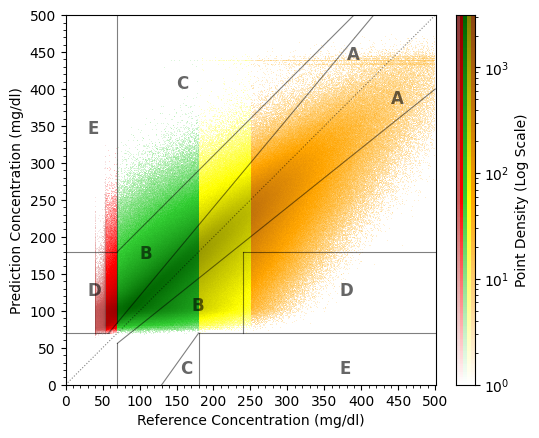

In [96]:
# A cycle for all parquet files
for df, model_name in zip([df_t1d_lstm, df_t1d_linear, df_t1d_cnn], ['LSTM_T1DiabetesGranada', 'Linear_T1DiabetesGranada', 'CNN_T1DiabetesGranada']):
    clarke_error_grid_striped_legend_english(df['y_test'], df['y_predict'], f'{model_name}_Colored_Legend')
    


In [86]:
df_replace_lstm = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_LSTM_H4.parquet')
df_replace_linear = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_Linear_H4.parquet')
df_replace_cnn = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/replace/df_test_results_vectors_RMSE_CNN_H4.parquet')

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

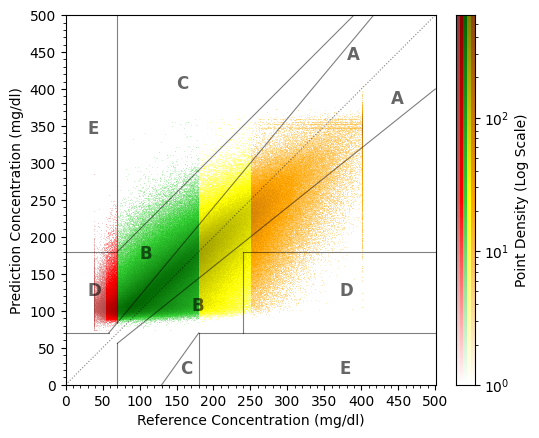

In [97]:
# Do the same now for replace
for df, model_name in zip([df_replace_lstm, df_replace_linear, df_replace_cnn], ['LSTM_Replace', 'Linear_Replace', 'CNN_Replace']):
    clarke_error_grid_striped_legend_english(df['y_test'], df['y_predict'], f'{model_name}_Colored_Legend')

In [88]:
# Read diatrend results
df_diatrend_lstm = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_LSTM_H4.parquet')
df_diatrend_linear = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_Linear_H4.parquet')
df_diatrend_cnn = pd.read_parquet('c:/Users/Ciro/C/_UGR_PDI/RELIEF-T1D/Glucose_prediction_2026/prediction_vectors/diatrend/df_test_results_vectors_RMSE_CNN_H4.parquet')


<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

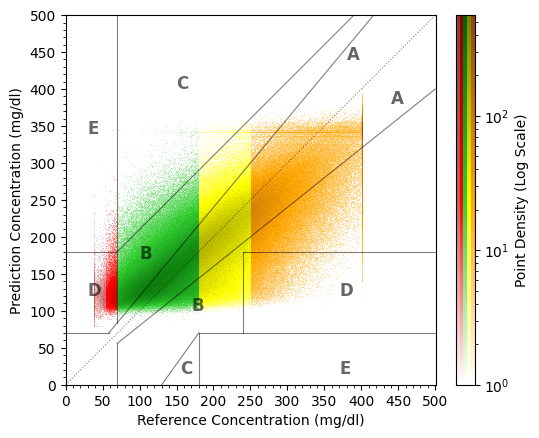

In [98]:
# do the same for diatrend
for df, model_name in zip([df_diatrend_lstm, df_diatrend_linear, df_diatrend_cnn], ['LSTM_Diatrend', 'Linear_Diatrend', 'CNN_Diatrend']):
    clarke_error_grid_striped_legend_english(df['y_test'], df['y_predict'], f'{model_name}_Colored_Legend')

In [48]:
df_t1d_lstm['y_test'].shape

(19421406,)

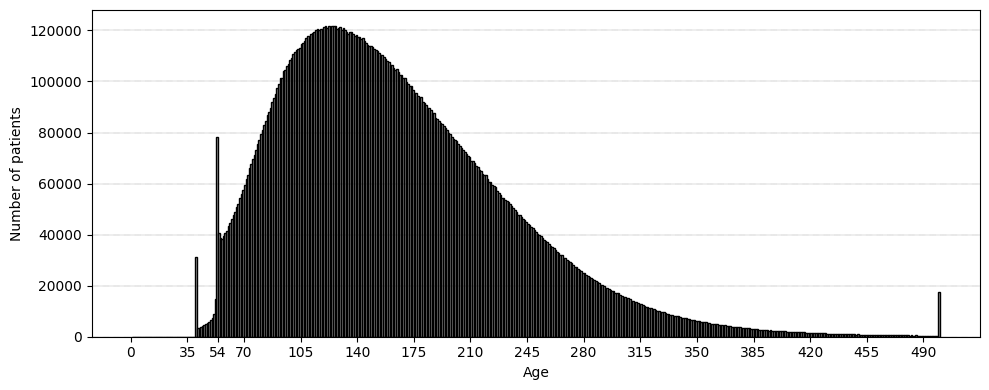

In [47]:
fig = plt.figure(figsize =(10, 4), tight_layout = True)
ax = fig.add_subplot(111)
bin_set = np.arange(1,501,1)
n, bins, patches = ax.hist(df_t1d_lstm['y_test'], histtype='bar', align='mid', bins=bin_set, color='darkgray', edgecolor = "black")
ax.grid(axis='y', linestyle=':', linewidth='0.3', color='black')

# bins_x = np.insert(bin_set, 0, [0 , 5])
bins_x = list(range(0, 504, 35))
bins_x = bins_x + [54]
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)
# 
# y_ticks_values = np.arange(0,101,10)
# y_ticks_labels = list(map(str, y_ticks_values))
# y_ticks = ax.yaxis.set_ticks(y_ticks_values)
# y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

# lim = ax.set_xlim(xmin=9, xmax=86)

y_title = ax.set_ylabel('Number of patients')
x_title = ax.set_xlabel('Age')
# fig.savefig('age.svg', dpi=900, bbox_inches='tight')

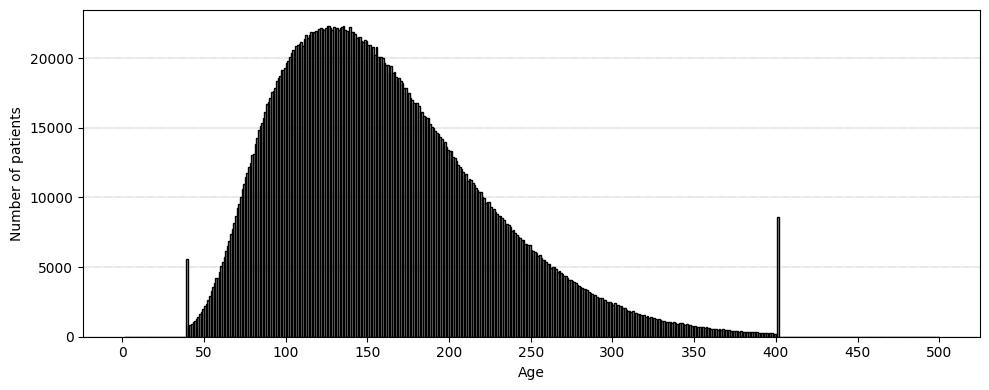

In [52]:
fig = plt.figure(figsize =(10, 4), tight_layout = True)
ax = fig.add_subplot(111)
bin_set = np.arange(1,501,1)
n, bins, patches = ax.hist(df_replace_lstm['y_test'], histtype='bar', align='mid', bins=bin_set, color='darkgray', edgecolor = "black")
ax.grid(axis='y', linestyle=':', linewidth='0.3', color='black')

# bins_x = np.insert(bin_set, 0, [0 , 5])
bins_x = list(range(0, 504, 50))
# bins_x = bins_x + [54]
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)
# 
# y_ticks_values = np.arange(0,101,10)
# y_ticks_labels = list(map(str, y_ticks_values))
# y_ticks = ax.yaxis.set_ticks(y_ticks_values)
# y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

# lim = ax.set_xlim(xmin=9, xmax=86)

y_title = ax.set_ylabel('Number of patients')
x_title = ax.set_xlabel('Age')
# fig.savefig('age.svg', dpi=900, bbox_inches='tight')

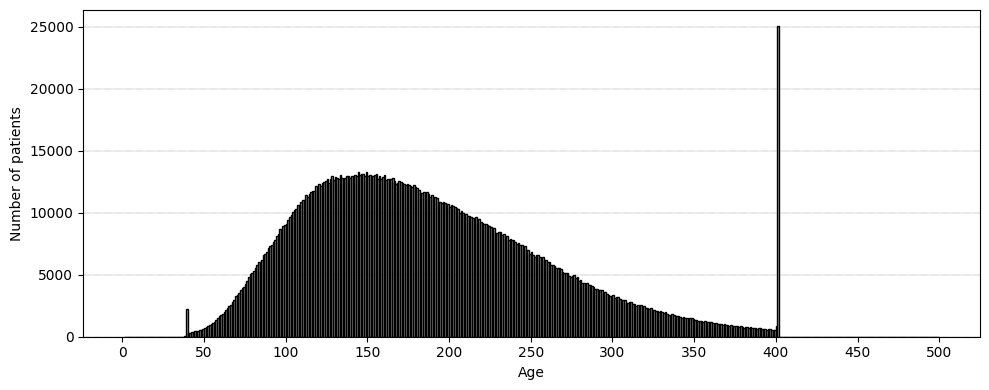

In [53]:
fig = plt.figure(figsize =(10, 4), tight_layout = True)
ax = fig.add_subplot(111)
bin_set = np.arange(1,501,1)
n, bins, patches = ax.hist(df_diatrend_lstm['y_test'], histtype='bar', align='mid', bins=bin_set, color='darkgray', edgecolor = "black")
ax.grid(axis='y', linestyle=':', linewidth='0.3', color='black')

# bins_x = np.insert(bin_set, 0, [0 , 5])
bins_x = list(range(0, 504, 50))
# bins_x = bins_x + [54]
x_ticks_labels = list(map(str, bins_x))
x_ticks = ax.xaxis.set_ticks(bins_x)
x_labels = ax.xaxis.set_ticklabels(x_ticks_labels)
# 
# y_ticks_values = np.arange(0,101,10)
# y_ticks_labels = list(map(str, y_ticks_values))
# y_ticks = ax.yaxis.set_ticks(y_ticks_values)
# y_labels = ax.yaxis.set_ticklabels(y_ticks_labels)

# lim = ax.set_xlim(xmin=9, xmax=86)

y_title = ax.set_ylabel('Number of patients')
x_title = ax.set_xlabel('Age')
# fig.savefig('age.svg', dpi=900, bbox_inches='tight')

ValueError: 'locs' must be 1D with shape (N,), but your input has shape ()

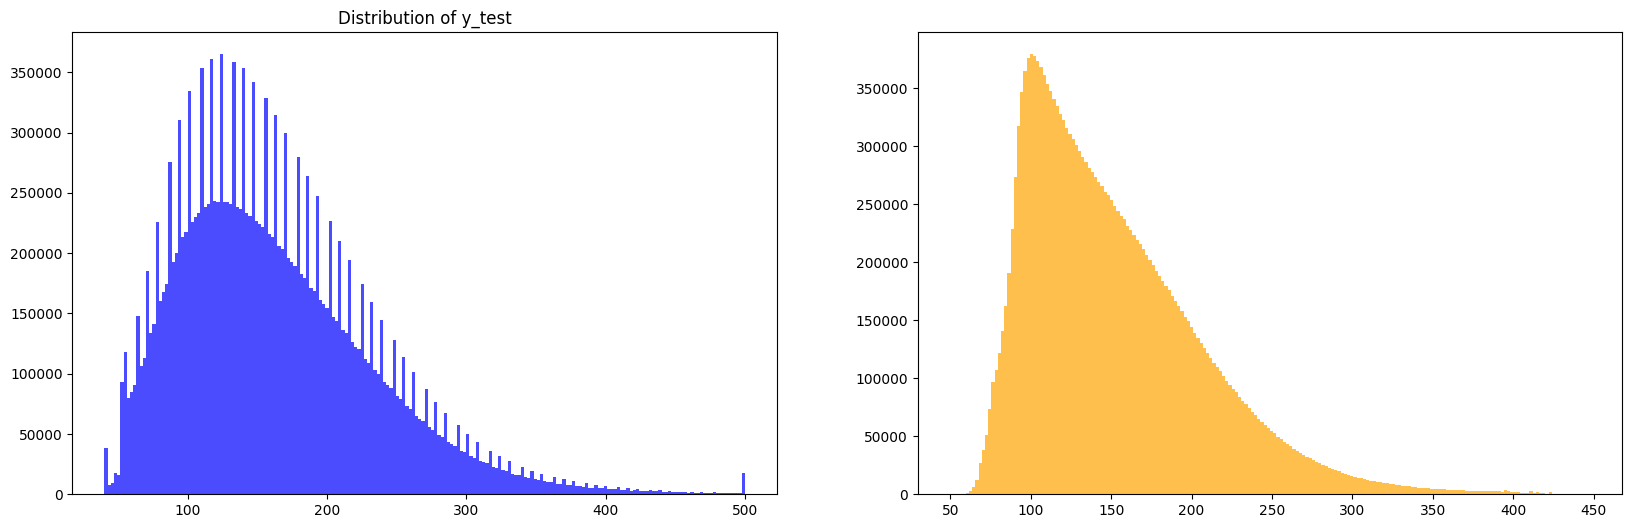

In [33]:
S# Histogram for y_test and y_predict
plt.figure(figsize=(20, 6))
plt.subplot(1, 2, 1)
plt.hist(df_t1d_lstm['y_test'], bins=200, color='blue', alpha=0.7)
plt.title('Distribution of y_test')
plt.subplot(1, 2, 2)
plt.hist(df_t1d_lstm['y_predict'], bins=200, color='orange', alpha=0.7)
plt.xticks(200, rotation=90)
plt.title('Distribution of y_predict')
# add more  x_ticks and xtick labels

plt.tight_layout()
plt.show()

In [24]:
# 1. Ver el valor máximo exacto que está prediciendo cada modelo
print("Max Predicción:", np.max(df_t1d_lstm['y_predict']))

# 2. Ver si hay muchos valores repetidos en el tope (Efecto Techo)
# Contamos cuántas veces se repiten los valores más altos
vals, counts = np.unique(np.round(df_t1d_lstm['y_predict']), return_counts=True)
print("Valores más frecuentes en rango alto:\n", list(zip(vals[-10:], counts[-10:])))

Max Predicción: 447.90448
Valores más frecuentes en rango alto:
 [(439.0, 24), (440.0, 19), (441.0, 13), (442.0, 15), (443.0, 4), (444.0, 8), (445.0, 8), (446.0, 5), (447.0, 3), (448.0, 2)]


# Normalized by dataset

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

def clarke_error_grid_normalized_by_dataset(ref_values, pred_values, title_string, 
                            vmin_manual=None, vmax_manual=None, 
                            plot_dir='plots_normalized_by_dataset'):
    
    if not os.path.exists(plot_dir):
        os.makedirs(plot_dir)
        
    plt.clf()
    fig, ax = plt.subplots() 

    # --- CONFIGURACIÓN DE BINS ---
    n_bins = 500
    my_range = [[0, 500], [0, 500]]
    my_bins = [n_bins, n_bins]

    # --- CÁLCULO DE LÍMITES (AUTOMÁTICO O MANUAL) ---
    # Si nos pasan los límites (vmin_manual), los usamos. Si no, calculamos.
    if vmin_manual is not None and vmax_manual is not None:
        vmin_global = vmin_manual
        vmax_global = vmax_manual
    else:
        # Cálculo local estándar si no se comparte escala
        h_temp = np.histogram2d(ref_values, pred_values, bins=my_bins, range=my_range)
        # El count mínimo siempre es 1 (para log), el máximo es el max del histograma
        vmin_global = 1 
        vmax_global = np.max(h_temp[0]) if np.max(h_temp[0]) > 0 else 10

    # Normalización compartida
    global_norm = LogNorm(vmin=vmin_global, vmax=vmax_global)

    # --- DEFINICIÓN DE COLORES ---
    cmap_tbr2 = LinearSegmentedColormap.from_list("custom_indian", ["#ffffff", "indianred", "#8B3A3A"]) 
    cmap_tbr1 = LinearSegmentedColormap.from_list("custom_red", ["#ffffff", "red", "#8B0000"])
    cmap_tir  = LinearSegmentedColormap.from_list("custom_lime", ["#ffffff", "limegreen", "#006400"])
    cmap_tar1 = LinearSegmentedColormap.from_list("custom_yellow", ["#ffffff", "yellow", "#808000"])
    cmap_tar2 = LinearSegmentedColormap.from_list("custom_orange", ["#ffffff", "orange", "#8B4513"])
    cmaps_ordered = [cmap_tbr2, cmap_tbr1, cmap_tir, cmap_tar1, cmap_tar2]

    # --- DIBUJO ---
    ranges = [
        (ref_values < 54, cmap_tbr2),
        ((ref_values >= 54) & (ref_values < 70), cmap_tbr1),
        ((ref_values >= 70) & (ref_values <= 180), cmap_tir),
        ((ref_values > 180) & (ref_values <= 250), cmap_tar1),
        (ref_values > 250, cmap_tar2)
    ]

    for mask, cmap in ranges:
        if np.any(mask):
            # Importante: pasamos norm=global_norm para respetar la escala compartida
            ax.hist2d(ref_values[mask], pred_values[mask],
                      bins=my_bins, range=my_range, cmap=cmap, cmin=1, norm=global_norm, zorder=2)

    # --- BARRA DE LEYENDA (Striped) ---
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.2) 

    n_steps = 200
    Y_bounds = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps + 1)
    Z_values = np.logspace(np.log10(vmin_global), np.log10(vmax_global), n_steps)
    Z_slice = Z_values.reshape(-1, 1)

    for i in range(5):
        X_bounds = np.array([i, i+1])
        X_mesh, Y_mesh = np.meshgrid(X_bounds, Y_bounds)
        cax.pcolormesh(X_mesh, Y_mesh, Z_slice, cmap=cmaps_ordered[i], norm=global_norm, shading='flat')

    cax.set_yscale('log')
    cax.set_xlim(0, 5)
    cax.yaxis.tick_right()
    # cax.yaxis.set_label_position("right")
    # cax.set_ylabel('Point Density (Log Scale)', rotation=90)
    cax.set_xticks([]) # Sin etiquetas abajo

    # --- ESTÉTICA FINAL (Inglés) ---
    lp = {'c': 'black', 'linewidth': 0.8, 'zorder': 10, 'alpha': 0.5}
    # lp = {'c': 'black', 'linewidth': 1}
    ax.plot([0, 500], [0, 500], ':', **lp)
    
    ax.plot([0, 175/3], [70, 70], '-', **lp)
    ax.plot([175/3, 500/1.2], [70, 500], '-', **lp)
    
    ax.plot([70, 70], [84, 500], '-', **lp)
    
    ax.plot([0, 70], [180, 180], '-', **lp)
    ax.plot([70, 390], [180, 500], '-', **lp)
    ax.plot([70, 70], [0, 56], '-', **lp)
    
    ax.plot([70, 500], [56, 400], '-', **lp)
    
    ax.plot([180, 180], [0, 70], '-', **lp)
    ax.plot([180, 500], [70, 70], '-', **lp)
    ax.plot([240, 240], [70, 180], '-', **lp)
    ax.plot([240, 500], [180, 180], '-', **lp)
    ax.plot([130, 180], [0, 70], '-', **lp)

    zones_ceg = [(380,440,"A"),(440,380,"A"),(170,100,"B"),(100,170,"B"),
                 (150,400,"C"),(155,15,"C"),(30,120,"D"),(370,120,"D"),(30,340,"E"),(370,15,"E")]
    for x, y, txt in zones_ceg:
        ax.text(x, y, txt, fontsize=12, fontweight='bold', color='black', alpha=0.6, zorder=11)
        # ax.text(x, y, txt, fontsize=12) #, fontweight='bold', color='black', alpha=0.6, zorder=11)

    ax.set_xlabel("Reference Concentration (mg/dl)")
    ax.set_ylabel("Prediction Concentration (mg/dl)")
    ax.set_xticks(np.arange(0, 551, 50)); ax.set_yticks(np.arange(0, 551, 50))
    ax.xaxis.set_minor_locator(MultipleLocator(10)); ax.yaxis.set_minor_locator(MultipleLocator(10))
    ax.set_xlim([0, 501]); ax.set_ylim([-1, 500])
    ax.set_aspect('equal')

    filename = f"{plot_dir}/CEG_SharedScale_{title_string}.png"
    plt.savefig(filename, dpi=900, bbox_inches='tight')
    plt.close()
    print(f"Generado: {filename}")

def process_dataset_row_shared_scale(model1_data, model2_data, model3_data, dataset_name):
    """
    Toma los datos de 3 modelos para un MISMO dataset, calcula la escala común y grafica.
    
    Cada argumento modelX_data debe ser una tupla o lista: (y_test, y_predict, "NombreModelo")
    """
    
    print(f"--- Procesando Dataset: {dataset_name} ---")
    
    # 1. Agrupar los datos para iterar
    all_models = [model1_data, model2_data, model3_data]
    
    # 2. Pre-cálculo: Encontrar la densidad máxima entre los 3 modelos
    max_densities = []
    
    for ref, pred, _ in all_models:
        # Usamos np.histogram2d solo para obtener los números, no graficamos nada aún
        # Es CRÍTICO usar los mismos bins que en la función de ploteo (500)
        H, _, _ = np.histogram2d(ref, pred, bins=[500, 500], range=[[0, 500], [0, 500]])
        max_densities.append(np.max(H))
    
    # Obtenemos el máximo absoluto de esta fila
    global_vmax = max(max_densities)
    global_vmin = 1  # Fijo en 1 porque es escala logarítmica
    
    print(f"Escala calculada para {dataset_name}: vmin={global_vmin}, vmax={global_vmax}")
    
    # 3. Generación de Gráficos usando la escala compartida
    for ref, pred, model_name in all_models:
        # Construimos un título único combinando Dataset y Modelo
        full_title = f"{dataset_name}_{model_name}"
        
        # Llamamos a la función base pasándole los límites calculados
        clarke_error_grid_normalized_by_dataset(ref, pred, full_title, 
                                vmin_manual=global_vmin, 
                                vmax_manual=global_vmax)


## Diatrend

In [11]:
process_dataset_row_shared_scale(
   (df_diatrend_linear['y_test'], df_diatrend_linear['y_predict'], f"Linear"),
   (df_diatrend_lstm['y_test'], df_diatrend_lstm['y_predict'], f"LSTM"),
   (df_diatrend_cnn['y_test'], df_diatrend_cnn['y_predict'], f"CNN"),
   "DiaTrend"
)

--- Procesando Dataset: DiaTrend ---
Escala calculada para DiaTrend: vmin=1, vmax=2055.0
Generado: plots_normalized_by_dataset/CEG_SharedScale_DiaTrend_Linear.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_DiaTrend_LSTM.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_DiaTrend_CNN.png


<Figure size 640x480 with 0 Axes>

## REPLACE-BG   

In [12]:
process_dataset_row_shared_scale(
   (df_replace_linear['y_test'], df_replace_linear['y_predict'], f"Linear"),
   (df_replace_lstm['y_test'], df_replace_lstm['y_predict'], f"LSTM"),
   (df_replace_cnn['y_test'], df_replace_cnn['y_predict'], f"CNN"),
   "REPLACE-BG"
)

--- Procesando Dataset: REPLACE-BG ---
Escala calculada para REPLACE-BG: vmin=1, vmax=924.0
Generado: plots_normalized_by_dataset/CEG_SharedScale_REPLACE-BG_Linear.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_REPLACE-BG_LSTM.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_REPLACE-BG_CNN.png


<Figure size 640x480 with 0 Axes>

## T1DiabetesGranada

In [13]:
process_dataset_row_shared_scale(
   (df_t1d_linear['y_test'], df_t1d_linear['y_predict'], f"Linear"),
   (df_t1d_lstm['y_test'], df_t1d_lstm['y_predict'], f"LSTM"),
   (df_t1d_cnn['y_test'], df_t1d_cnn['y_predict'], f"CNN"),
   "T1DiabetesGranada"
)

--- Procesando Dataset: T1DiabetesGranada ---
Escala calculada para T1DiabetesGranada: vmin=1, vmax=7213.0
Generado: plots_normalized_by_dataset/CEG_SharedScale_T1DiabetesGranada_Linear.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_T1DiabetesGranada_LSTM.png
Generado: plots_normalized_by_dataset/CEG_SharedScale_T1DiabetesGranada_CNN.png


<Figure size 640x480 with 0 Axes>

In [8]:
df_diatrend_linear['y_predict']

0          159.151428
1           89.277916
2          145.675140
3          153.541229
4          176.829224
              ...    
2304684    173.797379
2304685    170.828094
2304686    171.672867
2304687    171.806885
2304688    190.935211
Name: y_predict, Length: 2304689, dtype: float32